# Município vs Ajuste Direto

How much of municipal procurement is direct award, by **count** and by **value**?

- **Município:** adjudicante name, accent-folded and lowercased, starts with `municipio` (564 493 rows, 302 NIPC).
- **Ajuste Direto:** `tipo_procedimento` lowercased starts with `ajuste direto` (1 357 196 rows).

Caveats: 302 NIPCs vs 308 municipalities (the rule misses some and may include false positives); `Câmara Municipal …` is excluded.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import is_municipio_expr, load_contracts
from base_gov.entities import (
    canonical_names,
)
from base_gov.stats import MIN_VALUE, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet")
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts flagged is_below_min_value (|preco_contratual| < MIN_VALUE, €); contracts_all keeps them for before/after comparisons.
contracts = contracts_all.filter(~pl.col("is_below_min_value"))
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()

rows=2,295,074  cols=30
disregarded 12,658 contracts with |preco_contratual| < €10 (0.55%); kept 2,282,416
valor_por_dia defined for 97.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)


idcontrato,ano,adjudicante,adjudicante_nipc,adjudicante_name,adjudicante_key,adjudicante_key_source,adjudicatarios,objecto_contrato,desc_contrato,preco_contratual,preco_total_efetivo,preco_base_procedimento,prazo_execucao,valor_por_dia,data_celebracao,data_publicacao,data_fecho,tipo_contrato,tipo_procedimento,fundament_ajuste_direto,cpv,nuts,concorrentes,n_concorrentes,is_municipio,is_below_min_value,row_hash,first_ingested_at,updated_at
i64,i32,str,str,str,str,str,str,str,str,f64,f64,f64,i64,f64,date,date,date,str,str,str,str,str,str,u32,bool,bool,i64,"datetime[μs, UTC]","datetime[μs, UTC]"
11837094,2025,"""510103448 - Unidade Local de S…","""510103448""","""Unidade Local de Saúde de Coim…","""510103448""","""nipc""","""502248793 - MYLAN, LDA""","""EVEROLÍMUS 10 MG COMP""","""EVEROLÍMUS 10 MG COMP""",5469.24,0.0,5469.24,20,273.462,2025-09-08,2025-10-24,null,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""cpvID=33600000-6|cpvdescricao=…","""PT16E - Região de Coimbra""",null,null,false,false,-8325278450096791371,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
11941300,2025,"""510103448 - Unidade Local de S…","""510103448""","""Unidade Local de Saúde de Coim…","""510103448""","""nipc""","""508107997 - GENERIS""","""PREGABALINA 50 MG CÁPS""","""PREGABALINA 50 MG CÁPS""",176.4,0.0,224.28,20,8.82,2025-10-03,2025-11-12,null,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""cpvID=33600000-6|cpvdescricao=…","""PT16E - Região de Coimbra""",null,null,false,false,5147521430359512469,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
11593798,2025,"""510103448 - Unidade Local de S…","""510103448""","""Unidade Local de Saúde de Coim…","""510103448""","""nipc""","""- - BRIDGE TO LIFE EUROPE, LTO""","""0402-3091-2025 (Kits Perfusão …","""0402-3091-2025 (Kits Perfusão …",111000.0,111000.0,111000.0,20,5550.0,2025-07-09,2025-07-21,2025-07-21,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""cpvID=33000000-0|cpvdescricao=…","""PT16E - Região de Coimbra""",null,null,false,false,617016025134681594,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
11898049,2025,"""508481287 - Unidade Local de S…","""508481287""","""Unidade Local de Saúde de Sant…","""508481287""","""nipc""","""502120070 - KONICA MINOLTA BUS…","""Concurso Público com publicida…","""Concurso Público com publicida…",395100.0,0.0,395280.0,1096,360.492701,2025-10-31,2025-11-04,null,"""Aquisição de serviços""","""Concurso público""",null,"""cpvID=50310000-1|cpvdescricao=…","""PT170 - Área Metropolitana de …","""502120070-KONICA MINOLTA BUSIN…",1,false,false,8067913044914378299,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC
11968011,2025,"""506632920 - Município da Póvoa…","""506632920""","""Município da Póvoa de Lanhoso""","""506632920""","""nipc""","""- - Vanessa Fernanda Sá Pereir…",""" PRESTAÇÃO DE SERVIÇOS EM REGI…",""" PRESTAÇÃO DE SERVIÇOS EM REGI…",17400.0,0.0,17400.0,365,47.671233,2025-11-07,2025-11-20,null,"""Aquisição de serviços""","""Ajuste Direto Regime Geral""",null,"""cpvID=90000000-7|cpvdescricao=…","""PT119 - Ave""",null,null,true,false,1768699952337931715,2026-11-16 21:42:47.218292 UTC,2026-11-16 21:42:47.218292 UTC


In [3]:
AD_EXPR = pl.col("tipo_procedimento").str.to_lowercase().str.starts_with("ajuste direto")

In [4]:
contracts = contracts.with_columns(
    is_municipio_expr().alias("is_municipio"),
    AD_EXPR.alias("is_ajuste_direto"),
)
print(f"Município: {contracts['is_municipio'].sum():,}  Ajuste Direto: {contracts['is_ajuste_direto'].sum():,}")


Município: 564,493  Ajuste Direto: 1,357,196


In [5]:
cross = (
    contracts.group_by("is_municipio", "is_ajuste_direto")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().alias("total_value"))
    .sort("is_municipio", "is_ajuste_direto")
    .with_columns(
        (pl.col("n_contracts") / pl.col("n_contracts").sum().over("is_municipio") * 100).round(1).alias("row_pct_count"),
        (pl.col("total_value") / pl.col("total_value").sum().over("is_municipio") * 100).round(1).alias("row_pct_value"),
        (pl.col("n_contracts") / pl.col("n_contracts").sum().over("is_ajuste_direto") * 100).round(1).alias("col_pct_count"),
    )
)
assert cross["n_contracts"].sum() == contracts.height
for r in cross.iter_rows(named=True):
    print(f"municipio={r['is_municipio']!s:5} ad={r['is_ajuste_direto']!s:5} n={r['n_contracts']:>8,} value=€{r['total_value'] / 1e6:>10,.1f}M")
cross


municipio=False ad=None  n=       3 value=€       0.1M
municipio=False ad=False n= 713,955 value=€  92,017.6M
municipio=False ad=True  n=1,003,965 value=€  27,531.0M
municipio=True  ad=False n= 211,262 value=€  31,675.1M
municipio=True  ad=True  n= 353,231 value=€   8,205.8M


is_municipio,is_ajuste_direto,n_contracts,total_value,row_pct_count,row_pct_value,col_pct_count
bool,bool,u32,f64,f64,f64,f64
false,null,3,121525.0,0.0,0.0,100.0
false,false,713955,9.2018e10,41.6,77.0,77.2
false,true,1003965,2.7531e10,58.4,23.0,74.0
true,false,211262,3.1675e10,37.4,79.4,22.8
true,true,353231,8.2058e9,62.6,20.6,26.0


In [6]:
def procedure_mix(df: pl.DataFrame) -> pl.DataFrame:
    return (
        df.group_by("tipo_procedimento")
        .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
        .with_columns(
            (pl.col("n_contracts") / pl.col("n_contracts").sum() * 100).round(1).alias("pct_count"),
            (pl.col("total_value") / pl.col("total_value").sum() * 100).round(1).alias("pct_value"),
        )
        .sort("n_contracts", descending=True)
    )


mun = contracts.filter(pl.col("is_municipio"))
rest = contracts.filter(~pl.col("is_municipio"))
mun_mix = procedure_mix(mun)
ad_mun = mun.filter(pl.col("is_ajuste_direto"))
print(f"Município Ajuste Direto: {ad_mun.height:,} rows = {ad_mun.height / mun.height:.1%} by count, "
      f"{ad_mun['preco_contratual'].sum() / mun['preco_contratual'].sum():.1%} by value")
mun_mix


Município Ajuste Direto: 353,231 rows = 62.6% by count, 20.6% by value


tipo_procedimento,n_contracts,total_value,pct_count,pct_value
str,u32,f64,f64,f64
"""Ajuste Direto Regime Geral""",340916,8.1737e9,60.4,20.5
"""Consulta Prévia""",124109,4.8877e9,22.0,12.3
"""Concurso público""",74850,2.2631e10,13.3,56.7
"""Ajuste direto simplificado""",12211,3.0382e7,2.2,0.1
"""Ao abrigo de acordo-quadro (ar…",4636,1.7365e9,0.8,4.4
"""Ao abrigo de acordo-quadro (ar…",4070,1.0131e9,0.7,2.5
"""Contratação excluída II""",2398,4.1464e8,0.4,1.0
"""Consulta Prévia Simplificada""",665,1.0311e8,0.1,0.3
"""Concurso limitado por prévia q…",445,7.5864e8,0.1,1.9


In [7]:
# Effect of disregarding contracts with |value| below €10 on the two groups being compared.
all_flags = contracts_all.with_columns(is_municipio_expr().alias("is_municipio"), AD_EXPR.alias("is_ajuste_direto"))
print("Município:")
display(value_impact(all_flags.filter(pl.col("is_municipio")), mun))
print("Município Ajuste Direto:")
display(value_impact(all_flags.filter(pl.col("is_municipio") & pl.col("is_ajuste_direto")), ad_mun))

Município:


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",565806.0,564493.0,-1313.0,-0.23
"""mean_value""",70485.212927,70649.156603,163.943676,0.23
"""median_value""",16760.0,16800.0,40.0,0.24
"""total_value""",3.9881e10,3.9881e10,-2026.840004,-0.0


Município Ajuste Direto:


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",354011.0,353231.0,-780.0,-0.22
"""mean_value""",23179.609728,23230.78937,51.179643,0.22
"""median_value""",12000.0,12000.0,0.0,0.0
"""total_value""",8.2058e9,8.2058e9,-1859.2,-0.0


In [8]:
# Duration and value per day: Município Ajuste Direto vs other Município procedures vs rest.
groups = {"município AD": ad_mun, "município other": mun.filter(~pl.col("is_ajuste_direto")), "rest": rest}
display(pl.DataFrame([
    {"group": k, "n": g.height, "median_prazo_days": g["prazo_execucao"].median(),
     "median_value": g["preco_contratual"].median(), "median_eur_per_day": g["valor_por_dia"].median(),
     "value_per_day_defined": round(g["valor_por_dia"].is_not_null().mean(), 3)}
    for k, g in groups.items()
]))

group,n,median_prazo_days,median_value,median_eur_per_day,value_per_day_defined
str,i64,f64,f64,f64,f64
"""município AD""",353231,60.0,12000.0,211.333333,0.96
"""município other""",211262,180.0,39907.45,319.641096,0.997
"""rest""",1717923,113.0,8696.7,88.571429,0.98


In [9]:
print("Non-Município adjudicantes:")
rest_mix = procedure_mix(rest)
rest_mix


Non-Município adjudicantes:


tipo_procedimento,n_contracts,total_value,pct_count,pct_value
str,u32,f64,f64,f64
"""Ajuste Direto Regime Geral""",975188,2.7371e10,56.8,22.9
"""Ao abrigo de acordo-quadro (ar…",220645,1.7837e10,12.8,14.9
"""Consulta Prévia""",207868,5.8217e9,12.1,4.9
"""Concurso público""",192130,5.4137e10,11.2,45.3
"""Ao abrigo de acordo-quadro (ar…",45582,2.2811e9,2.7,1.9
"""Contratação excluída II""",37754,2.4765e9,2.2,2.1
"""Ajuste direto simplificado""",25724,1.4510e8,1.5,0.1
"""Concurso limitado por prévia q…",3936,6.7068e9,0.2,5.6
"""Setores especiais – isenção pa…",3934,2.6919e8,0.2,0.2


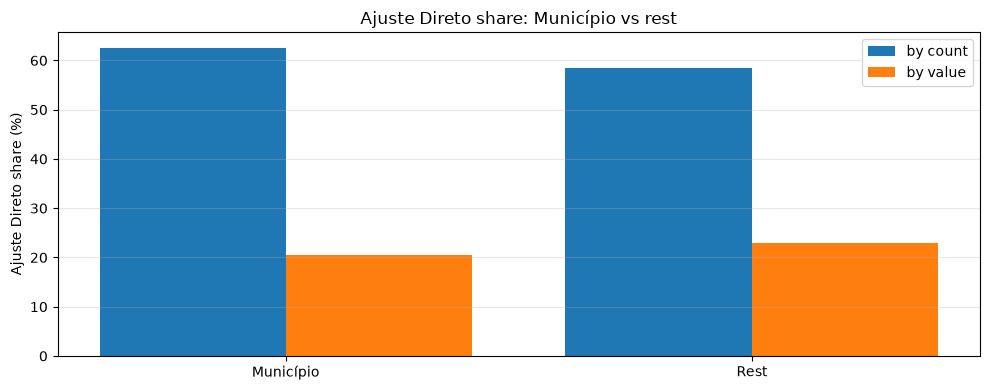

In [10]:
import numpy as np

def ad_shares(df: pl.DataFrame) -> tuple[float, float]:
    ad = df.filter(pl.col("is_ajuste_direto"))
    return ad.height / df.height * 100, ad["preco_contratual"].sum() / df["preco_contratual"].sum() * 100

shares = {"Município": ad_shares(mun), "Rest": ad_shares(rest)}
x = np.arange(2)
fig, ax = plt.subplots()
ax.bar(x - 0.2, [s[0] for s in shares.values()], 0.4, label="by count")
ax.bar(x + 0.2, [s[1] for s in shares.values()], 0.4, label="by value")
ax.set_xticks(x, list(shares))
ax.set_ylabel("Ajuste Direto share (%)")
ax.set_title("Ajuste Direto share: Município vs rest")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


In [11]:
per_mun = (
    mun.group_by("adjudicante_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("is_ajuste_direto").mean().alias("ad_share"),
    )
    .filter(pl.col("n_contracts") >= 50)  # avoid small-denominator noise
    .join(canonical_names(mun, prefix="adjudicante"), on="adjudicante_key", how="left")
)
assert per_mun["ad_share"].is_between(0, 1).all()
print(f"{per_mun.height} municipalities with >= 50 contracts")
print("Highest AD share:")
display(per_mun.sort("ad_share", descending=True).head(15))
print("\nLowest AD share:")
display(per_mun.sort("ad_share").head(15))


301 municipalities with >= 50 contracts
Highest AD share:


adjudicante_key,n_contracts,ad_share,adjudicante_name
str,u32,f64,str
"""512074410""",1419,0.96265,"""Município de Lagoa (Açores)"""
"""512074089""",307,0.928339,"""Município de Calheta - São Jor…"
"""512043701""",414,0.910628,"""Município de Vila Franca do Ca…"
"""512073821""",580,0.910345,"""Município da Horta"""
"""506613461""",1896,0.852321,"""Município de Vila Viçosa"""
"""512044023""",465,0.847312,"""Município da Praia da Vitória"""
"""506659968""",984,0.844512,"""Município do Crato"""
"""501175229""",1786,0.839306,"""Município de Campo Maior"""
"""506824942""",1293,0.821346,"""Município de Sabrosa"""



Lowest AD share:


adjudicante_key,n_contracts,ad_share,adjudicante_name
str,u32,f64,str
"""505377802""",1201,0.352206,"""Município de Proença-a-Nova"""
"""511217315""",2341,0.378898,"""Município do Funchal"""
"""512070946""",437,0.384439,"""Município da Madalena"""
"""501157280""",2980,0.39396,"""Município de Santa Maria da Fe…"
"""501205551""",2555,0.406654,"""Município de Chaves"""
"""501937471""",1210,0.409091,"""Município de Monção"""
"""506215547""",2456,0.418567,"""Municipio de Bragança"""
"""501073655""",1990,0.423116,"""Município do Marco de Canavese…"
"""505211696""",1758,0.430603,"""Município de Arcos de Valdevez"""


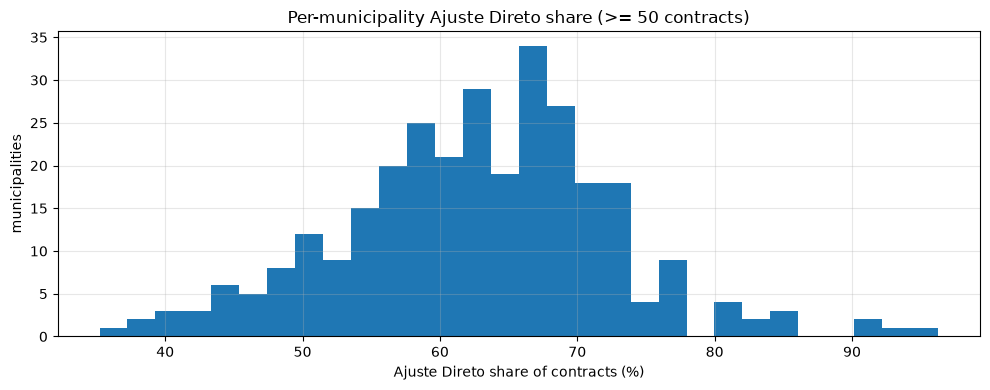

In [12]:
fig, ax = plt.subplots()
ax.hist(per_mun["ad_share"].to_numpy() * 100, bins=30)
ax.set_xlabel("Ajuste Direto share of contracts (%)")
ax.set_ylabel("municipalities")
ax.set_title("Per-municipality Ajuste Direto share (>= 50 contracts)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:
(
    mun.group_by("is_ajuste_direto")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("preco_contratual").mean().alias("mean_value"),
        pl.col("preco_contratual").sum().alias("total_value"),
    )
    .sort("is_ajuste_direto")
)


is_ajuste_direto,n_contracts,median_value,mean_value,total_value
bool,u32,f64,f64,f64
false,211262,39907.45,149932.876705,3.1675e10
true,353231,12000.0,23230.78937,8.2058e9


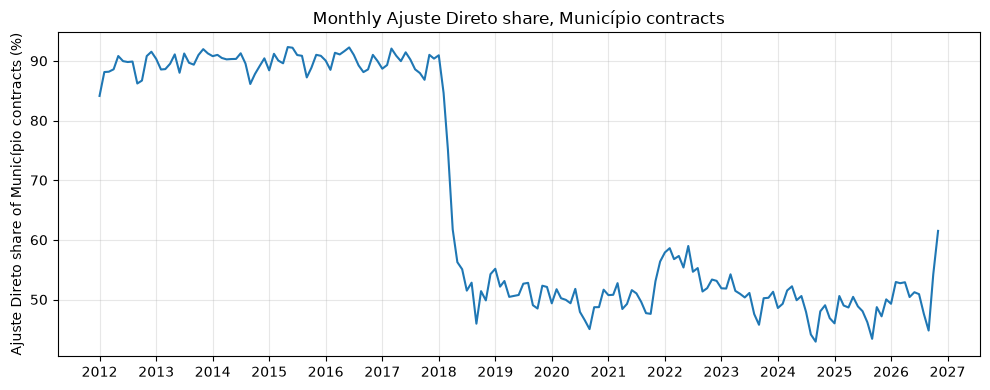

In [14]:
mm = (
    mun.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg((pl.col("is_ajuste_direto").mean() * 100).alias("ad_share"), pl.len().alias("n_contracts"))
    .sort("month")
)
fig, ax = plt.subplots()
ax.plot(mm["month"], mm["ad_share"])
ax.set_ylabel("Ajuste Direto share of Município contracts (%)")
ax.set_title("Monthly Ajuste Direto share, Município contracts")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Commentary and limitations

Direct award dominates municipal procurement by **count** (about half of contracts) but far less by **value**
(about an eighth): many small contracts go through Ajuste Direto while the large spend goes through
competitive procedures.

Limitations: 2012–2026, data up to 2026-11-14 (partial edge months); the Município rule may include false positives;
no per-contract legal-threshold validation.
Municipalities are keyed by NIPC (`adjudicante_key`), so the `>= 50` filter now counts each entity once
instead of once per name spelling.


Contracts with |value| below €10 are disregarded; `valor_por_dia` uses only 1–3650-day durations.